# Project 1 — Cancer Gene Expression Explorer
### A beginner-friendly bioinformatics investigation using public breast cancer data

**Research question:** Which genes show the clearest expression differences between breast cancer tissue and normal breast tissue in the GSE42568 dataset?

**Dataset source:** NCBI Gene Expression Omnibus (GEO), accession [GSE42568](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE42568).

**Study design:** The GEO record describes 104 breast cancer biopsies and 17 normal breast tissue samples, measured using the Affymetrix Human Genome U133 Plus 2.0 microarray (GPL570).

**What this notebook will do**
1. Download the processed expression matrix and platform annotation from NCBI GEO.
2. Inspect sample labels and confirm tumour/normal group counts.
3. Map microarray probe IDs to gene symbols and create a gene-level table.
4. Compare expression between the two groups using an appropriate simple statistical test.
5. Correct for testing many genes using the Benjamini–Hochberg false-discovery-rate procedure.
6. Visualise the results and export tables and figures.

**Important interpretation note:** This is an exploratory analysis of one historical microarray dataset. Differential expression does not prove that a gene causes cancer, and results should not be described as a clinically validated biomarker. The notebook reports what the data support and includes limitations.

## 1. Set up the environment



In [1]:
import os, re, gzip, csv, io, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

SEED = 42
OUTDIR = Path("project1_outputs")
OUTDIR.mkdir(exist_ok=True)

print("Environment ready.")
print("Output folder:", OUTDIR.resolve())

Environment ready.
Output folder: /content/project1_outputs


## 2. Download the public dataset

The files are hosted by NCBI GEO. We download the processed expression matrix and GPL570 platform annotation. If NCBI is temporarily unavailable, rerun this cell later.

In [2]:
SERIES_URL = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE42nnn/GSE42568/matrix/GSE42568_series_matrix.txt.gz"
ANNOT_URL = "https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPLnnn/GPL570/annot/GPL570.annot.gz"

series_path = Path("GSE42568_series_matrix.txt.gz")
annot_path = Path("GPL570.annot.gz")

def download_if_missing(url, path):
    if path.exists() and path.stat().st_size > 0:
        print(f"Already downloaded: {path} ({path.stat().st_size:,} bytes)")
        return
    print(f"Downloading {path.name} ...")
    urllib.request.urlretrieve(url, path)
    print(f"Saved {path} ({path.stat().st_size:,} bytes)")

download_if_missing(SERIES_URL, series_path)
download_if_missing(ANNOT_URL, annot_path)

Saved GSE42568_series_matrix.txt.gz (22,565,943 bytes)
Saved GPL570.annot.gz (8,471,521 bytes)


## 3. Read the expression matrix and sample metadata

GEO series matrix files contain both sample annotations and an expression table. This cell extracts the table and the sample titles, then labels samples using the GEO titles.

In [3]:
with gzip.open(series_path, "rt", encoding="utf-8", errors="replace") as f:
    lines = f.readlines()

begin_idx = next((i for i, line in enumerate(lines) if line.strip() == "!series_matrix_table_begin"), None)
end_idx = next((i for i, line in enumerate(lines) if line.strip() == "!series_matrix_table_end"), None)
if begin_idx is None or end_idx is None or end_idx <= begin_idx:
    raise ValueError("Could not locate the expression table in the GEO series matrix file.")

matrix_text = "".join(lines[begin_idx + 1:end_idx])
probe_by_sample = pd.read_csv(io.StringIO(matrix_text), sep="\t", dtype={"ID_REF": str})
probe_by_sample = probe_by_sample.set_index("ID_REF")
probe_by_sample = probe_by_sample.apply(pd.to_numeric, errors="coerce")

def parse_geo_metadata(lines, key):
    prefix = f"!Sample_{key}\t"
    for line in lines:
        if line.startswith(prefix):
            vals = next(csv.reader([line.rstrip("\n")], delimiter="\t", quotechar='"'))[1:]
            return vals
    return None

titles = parse_geo_metadata(lines, "title")
if titles is None:
    raise ValueError("Could not find !Sample_title in the GEO file.")
if len(titles) != probe_by_sample.shape[1]:
    raise ValueError(f"Sample metadata count ({len(titles)}) does not match expression columns ({probe_by_sample.shape[1]}).")

sample_meta = pd.DataFrame({
    "sample_id": probe_by_sample.columns.astype(str),
    "title": titles
})
sample_meta["group"] = np.select(
    [
        sample_meta["title"].str.contains(r"normal breast", case=False, regex=True),
        sample_meta["title"].str.contains(r"breast cancer", case=False, regex=True),
    ],
    ["Normal", "Tumour"],
    default="Unclassified"
)

print("Expression matrix shape (probes × samples):", probe_by_sample.shape)
display(sample_meta.groupby("group").size().rename("sample_count").to_frame())
display(sample_meta.head(10))

Expression matrix shape (probes × samples): (54675, 121)


,sample_count
group,
Normal,17
Tumour,104


,sample_id,title,group
0,GSM1045191,"Normal breast, N1_15_12_04",Normal
1,GSM1045192,"Normal breast, N4_14_12_04",Normal
2,GSM1045193,"Normal breast, N5_15_12_04",Normal
3,GSM1045194,"Normal breast, N6_14_12_04",Normal
4,GSM1045195,"Normal breast, P1_15_12_04",Normal
5,GSM1045196,"Normal breast, P10_26_1_05",Normal
6,GSM1045197,"Normal breast, P11_25_1_05",Normal
7,GSM1045198,"Normal breast, P12_25_1_05",Normal
8,GSM1045199,"Normal breast, P13_25_1_05",Normal
9,GSM1045200,"Normal breast, P14_25_1_05",Normal


### Quality check: sample labels

We expect 17 normal breast samples and 104 breast cancer samples according to the GEO study description.

In [4]:
group_counts = sample_meta["group"].value_counts().to_dict()
print("Observed group counts:", group_counts)

if "Unclassified" in group_counts and group_counts["Unclassified"] > 0:
    print("\nUnclassified sample titles:")
    display(sample_meta.loc[sample_meta["group"] == "Unclassified", ["sample_id", "title"]])
    raise ValueError("Some samples were not classified. Inspect titles and adjust the label rule before analysis.")

if group_counts.get("Normal", 0) != 17 or group_counts.get("Tumour", 0) != 104:
    print("WARNING: Counts differ from the GEO study summary. Verify the metadata and labels before interpreting results.")
else:
    print("Sample counts match the GEO study summary.")

Observed group counts: {'Tumour': 104, 'Normal': 17}
Sample counts match the GEO study summary.


## 4. Map probes to gene symbols

Microarrays measure probe sets, not always one unique gene per row. We use the platform annotation to map probe IDs to gene symbols, then collapse multiple probes for a gene by keeping the probe with the highest variance across samples. This is a transparent simplification for a learning project; it is not a full reprocessing of raw microarray data.

In [5]:
# The GPL570 annotation file contains metadata lines before its tabular header.
# Starting pandas at the very first non-comment line can trigger a ParserError.
with gzip.open(annot_path, "rt", encoding="utf-8", errors="replace") as f:
    annot_lines = f.readlines()

header_idx = None
for i, line in enumerate(annot_lines):
    fields = line.rstrip("\r\n").split("\t")
    if len(fields) >= 5 and fields[0].strip().lower() in {"id", "probe set id", "probe set name"}:
        # Platform annotation header: a multi-column row beginning with the probe identifier.
        if any("gene symbol" in field.lower() or field.strip().lower() == "symbol" for field in fields):
            header_idx = i
            break

if header_idx is None:
    preview = "\n".join(f"{i+1}: {line.rstrip()[:180]}" for i, line in enumerate(annot_lines[:40]))
    raise ValueError(
        "Could not find the tabular header in GPL570.annot.gz. "
        "The first 40 lines are printed below for diagnosis:\\n" + preview
    )

annot_text = "".join(annot_lines[header_idx:])
annot = pd.read_csv(
    io.StringIO(annot_text),
    sep="\t",
    dtype=str,
    low_memory=False,
    on_bad_lines="skip"
)
print("Annotation columns (first 30):", annot.columns.tolist()[:30])
display(annot.head(3))

def find_column(columns, candidates):
    lower_map = {str(c).strip().lower(): c for c in columns}
    for cand in candidates:
        if cand.lower() in lower_map:
            return lower_map[cand.lower()]
    for c in columns:
        cl = str(c).strip().lower()
        if any(cand.lower() in cl for cand in candidates):
            return c
    return None

id_col = find_column(annot.columns, ["ID", "ID_REF", "Probe Set ID", "Probe Set Name"])
symbol_col = find_column(annot.columns, ["Gene Symbol", "Gene symbol", "Symbol"])
if id_col is None or symbol_col is None:
    raise ValueError("Could not identify probe ID and gene-symbol columns in GPL570 annotation. Inspect the displayed columns.")

annot_small = annot[[id_col, symbol_col]].copy()
annot_small.columns = ["probe_id", "gene_symbol"]
annot_small["probe_id"] = annot_small["probe_id"].astype(str).str.strip()
annot_small["gene_symbol"] = annot_small["gene_symbol"].fillna("").astype(str).str.strip()
annot_small = annot_small[
    annot_small["gene_symbol"].ne("") &
    ~annot_small["gene_symbol"].isin(["---", "NA", "null"])
].drop_duplicates("probe_id")

# Some annotation rows contain multiple symbols separated by ///; retain the first listed symbol.
annot_small["gene_symbol"] = annot_small["gene_symbol"].str.split(r"\s*///\s*").str[0].str.strip()

expr = probe_by_sample.join(annot_small.set_index("probe_id"), how="inner")
expr = expr.dropna(subset=["gene_symbol"])
expr = expr[~expr["gene_symbol"].eq("")]
sample_cols = probe_by_sample.columns.tolist()

# Keep one probe per gene: the probe with the greatest variance across samples.
expr["probe_variance"] = expr[sample_cols].var(axis=1, skipna=True)
expr = expr.sort_values("probe_variance", ascending=False)
gene_expr = expr.drop_duplicates("gene_symbol", keep="first").set_index("gene_symbol")[sample_cols]

print("Mapped probes:", len(annot_small))
print("Unique genes after collapsing probes:", gene_expr.shape[0])
display(gene_expr.iloc[:5, :5])

Annotation columns (first 30): ['ID', 'Gene title', 'Gene symbol', 'Gene ID', 'UniGene title', 'UniGene symbol', 'UniGene ID', 'Nucleotide Title', 'GI', 'GenBank Accession', 'Platform_CLONEID', 'Platform_ORF', 'Platform_SPOTID', 'Chromosome location', 'Chromosome annotation', 'GO:Function', 'GO:Process', 'GO:Component', 'GO:Function ID', 'GO:Process ID', 'GO:Component ID']


,ID,Gene title,Gene symbol,Gene ID,UniGene title,UniGene symbol,UniGene ID,Nucleotide Title,GI,GenBank Accession,...,Platform_ORF,Platform_SPOTID,Chromosome location,Chromosome annotation,GO:Function,GO:Process,GO:Component,GO:Function ID,GO:Process ID,GO:Component ID
0,1007_s_at,microRNA 4640///discoidin domain receptor tyro...,MIR4640///DDR1,100616237///780,NaN,NaN,NaN,"Human receptor tyrosine kinase DDR gene, compl...",1753221,U48705,...,NaN,NaN,6p21.3,"Chromosome 6, NC_000006.12 (30890883..30890972...",ATP binding///collagen binding///collagen bind...,branching involved in mammary gland duct morph...,basolateral plasma membrane///extracellular ex...,GO:0005524///GO:0005518///GO:0005518///GO:0046...,GO:0060444///GO:0007155///GO:0038063///GO:0038...,GO:0016323///GO:0070062///GO:0005615///GO:0005...
1,1053_at,replication factor C subunit 2,RFC2,5982,NaN,NaN,NaN,"Human replication factor C, 40-kDa subunit (A1...",1590810,M87338,...,NaN,NaN,7q11.23,"Chromosome 7, NC_000007.14 (74231502..74254458...",ATP binding///contributes_to DNA clamp loader ...,"DNA damage response, detection of DNA damage//...",Ctf18 RFC-like complex///DNA replication facto...,GO:0005524///contributes_to GO:0003689///GO:00...,GO:0042769///GO:0006260///GO:0070987///GO:0042...,GO:0031390///GO:0005663///GO:0005654
2,117_at,heat shock protein family A (Hsp70) member 6,HSPA6,3310,NaN,NaN,NaN,Human heat-shock protein HSP70B' gene,35221,X51757,...,NaN,NaN,1q23,"Chromosome 1, NC_000001.11 (161524540..161526897)","ATP binding///ATPase activity, coupled///enzym...",NOT cellular heat acclimation///cellular respo...,colocalizes_with COP9 signalosome///blood micr...,GO:0005524///GO:0042623///GO:0019899///GO:0031...,NOT GO:0070370///GO:0034605///GO:0034605///GO:...,colocalizes_with GO:0008180///GO:0072562///GO:...


Mapped probes: 45118
Unique genes after collapsing probes: 21755


,GSM1045191,GSM1045192,GSM1045193,GSM1045194,GSM1045195
gene_symbol,,,,,
SCGB2A2,11.790325,10.747524,3.307408,9.794524,8.981592
CPB1,12.434862,4.591932,2.639328,2.639328,4.841131
FABP4,13.536905,12.887341,2.384673,12.018879,13.899246
TFAP2B,8.031884,4.860677,2.909965,9.965290,2.909965
MUCL1,14.077037,11.250686,5.457254,12.805334,10.328329


## 5. Explore expression values

We first inspect the overall distribution of processed expression values. The series matrix contains processed values, so this project does not start from raw microarray intensities.

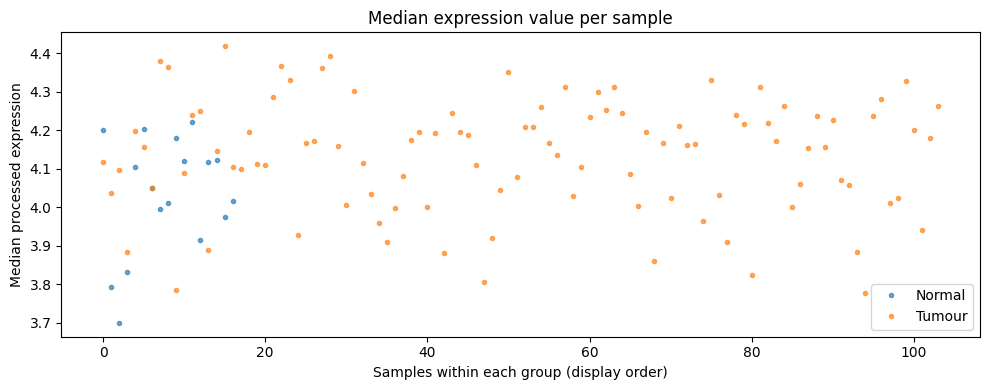

Expression value summary:


,value
count,2.632355e+06
mean,4.730912e+00
std,2.482226e+00
min,2.312812e+00
25%,2.334891e+00
50%,4.097968e+00
75%,6.556082e+00
max,1.604690e+01


In [6]:
sample_groups = sample_meta.set_index("sample_id").loc[gene_expr.columns, "group"]
sample_groups = sample_groups.astype(str)

plt.figure(figsize=(10, 4))
for group in ["Normal", "Tumour"]:
    cols = sample_groups.index[sample_groups.eq(group)]
    if len(cols):
        plt.plot(gene_expr[cols].median(axis=0).values, ".", alpha=0.65, label=group)
plt.title("Median expression value per sample")
plt.xlabel("Samples within each group (display order)")
plt.ylabel("Median processed expression")
plt.legend()
plt.tight_layout()
plt.savefig(OUTDIR / "sample_median_expression.png", dpi=160)
plt.show()

print("Expression value summary:")
display(gene_expr.stack().describe().to_frame("value"))

## 6. Compare tumour and normal samples

For each gene, we calculate the difference in mean processed expression (Tumour − Normal) and perform a Welch two-sample t-test. Because thousands of genes are tested, we adjust p-values using the Benjamini–Hochberg method. The adjusted p-value is called the false discovery rate (FDR) q-value in the output.

**Caution:** this is a simple exploratory analysis. It does not adjust for clinical covariates, and the normal and tumour groups may differ in more than cancer status.

In [7]:
normal_cols = sample_groups.index[sample_groups.eq("Normal")].tolist()
tumour_cols = sample_groups.index[sample_groups.eq("Tumour")].tolist()
if len(normal_cols) < 2 or len(tumour_cols) < 2:
    raise ValueError("Not enough samples in one or both groups to compare expression.")

results = []
for gene, row in gene_expr.iterrows():
    normal_vals = row[normal_cols].astype(float).dropna().values
    tumour_vals = row[tumour_cols].astype(float).dropna().values
    if len(normal_vals) < 2 or len(tumour_vals) < 2:
        continue
    stat, pval = ttest_ind(tumour_vals, normal_vals, equal_var=False, nan_policy="omit")
    results.append({
        "gene_symbol": gene,
        "mean_normal": float(np.mean(normal_vals)),
        "mean_tumour": float(np.mean(tumour_vals)),
        "mean_difference_tumour_minus_normal": float(np.mean(tumour_vals) - np.mean(normal_vals)),
        "t_statistic": float(stat),
        "p_value": float(pval)
    })

de = pd.DataFrame(results).dropna(subset=["p_value"])
de["FDR_q_value"] = multipletests(de["p_value"].values, method="fdr_bh")[1]
de["-log10_FDR"] = -np.log10(de["FDR_q_value"].clip(lower=1e-300))
de["direction"] = np.where(de["mean_difference_tumour_minus_normal"] > 0, "Higher in tumour", "Higher in normal")
de = de.sort_values(["FDR_q_value", "p_value"]).reset_index(drop=True)

print("Genes tested:", len(de))
print("Genes with FDR q < 0.05:", int((de["FDR_q_value"] < 0.05).sum()))
display(de.head(20))

/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
/usr/local/lib/python3.13/dist-packages/scipy/stats/_axis_nan_policy.py:579: RuntimeWarning: Precision loss occurred in moment 

Genes tested: 21737
Genes with FDR q < 0.05: 8895


,gene_symbol,mean_normal,mean_tumour,mean_difference_tumour_minus_normal,t_statistic,p_value,FDR_q_value,-log10_FDR,direction
0,COL10A1,3.397893,6.990270,3.592377,18.788705,2.381322e-37,5.176280e-33,32.285982,Higher in tumour
1,NECTIN4,3.446957,5.311889,1.864932,15.448086,3.469596e-30,3.770930e-26,25.423552,Higher in tumour
2,RAB15,2.661644,4.340283,1.678639,14.041995,1.012895e-26,7.339102e-23,22.134357,Higher in tumour
3,GTF2IRD2,3.097402,5.224561,2.127159,14.565260,6.714834e-26,3.481228e-22,21.458268,Higher in tumour
4,FBXL16,4.023494,7.077863,3.054369,15.062102,8.007609e-26,3.481228e-22,21.458268,Higher in tumour
5,MMP11,3.537390,6.942168,3.404778,15.485329,4.797246e-25,1.737962e-21,20.759960,Higher in tumour
6,FGFR3,4.008316,6.827279,2.818963,12.808203,4.403054e-24,1.245523e-20,19.904648,Higher in tumour
7,HELLS,2.699310,4.809621,2.110311,13.371521,4.583973e-24,1.245523e-20,19.904648,Higher in tumour
8,RSPH1,2.881538,4.743672,1.862135,12.743071,6.887049e-24,1.663375e-20,19.779010,Higher in tumour
9,TRIM45,2.832317,4.956712,2.124395,13.738983,1.491806e-23,3.242739e-20,19.489088,Higher in tumour


## 7. Visualise the findings

A volcano plot shows the size and statistical evidence of expression differences. It is a summary view, not proof that any gene is clinically useful.

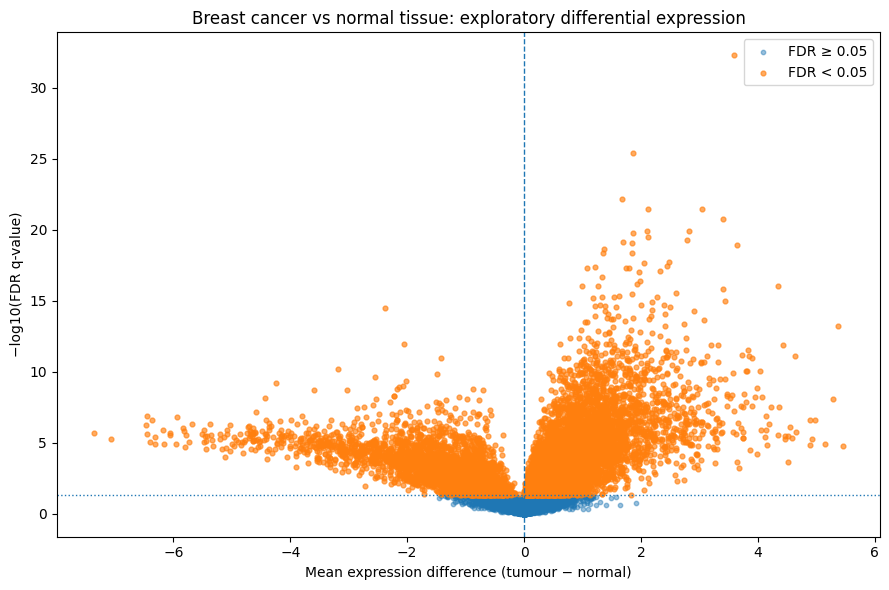

In [8]:
plt.figure(figsize=(9, 6))
sig = de["FDR_q_value"] < 0.05
plt.scatter(
    de.loc[~sig, "mean_difference_tumour_minus_normal"],
    de.loc[~sig, "-log10_FDR"],
    s=10, alpha=0.45, label="FDR ≥ 0.05"
)
plt.scatter(
    de.loc[sig, "mean_difference_tumour_minus_normal"],
    de.loc[sig, "-log10_FDR"],
    s=12, alpha=0.65, label="FDR < 0.05"
)
plt.axvline(0, linestyle="--", linewidth=1)
plt.axhline(-np.log10(0.05), linestyle=":", linewidth=1)
plt.xlabel("Mean expression difference (tumour − normal)")
plt.ylabel("−log10(FDR q-value)")
plt.title("Breast cancer vs normal tissue: exploratory differential expression")
plt.legend()
plt.tight_layout()
plt.savefig(OUTDIR / "volcano_plot.png", dpi=180)
plt.show()

## 8. Inspect the top-ranked genes

Look at both the statistical ranking and the size/direction of the expression difference. Do not assume the top-ranked gene is automatically the most important biologically.

,gene_symbol,mean_normal,mean_tumour,mean_difference_tumour_minus_normal,p_value,FDR_q_value,direction
0,COL10A1,3.397893,6.990270,3.592377,2.381322e-37,5.176280e-33,Higher in tumour
1,NECTIN4,3.446957,5.311889,1.864932,3.469596e-30,3.770930e-26,Higher in tumour
2,RAB15,2.661644,4.340283,1.678639,1.012895e-26,7.339102e-23,Higher in tumour
3,GTF2IRD2,3.097402,5.224561,2.127159,6.714834e-26,3.481228e-22,Higher in tumour
4,FBXL16,4.023494,7.077863,3.054369,8.007609e-26,3.481228e-22,Higher in tumour
5,MMP11,3.537390,6.942168,3.404778,4.797246e-25,1.737962e-21,Higher in tumour
6,FGFR3,4.008316,6.827279,2.818963,4.403054e-24,1.245523e-20,Higher in tumour
7,HELLS,2.699310,4.809621,2.110311,4.583973e-24,1.245523e-20,Higher in tumour
8,RSPH1,2.881538,4.743672,1.862135,6.887049e-24,1.663375e-20,Higher in tumour
9,TRIM45,2.832317,4.956712,2.124395,1.491806e-23,3.242739e-20,Higher in tumour


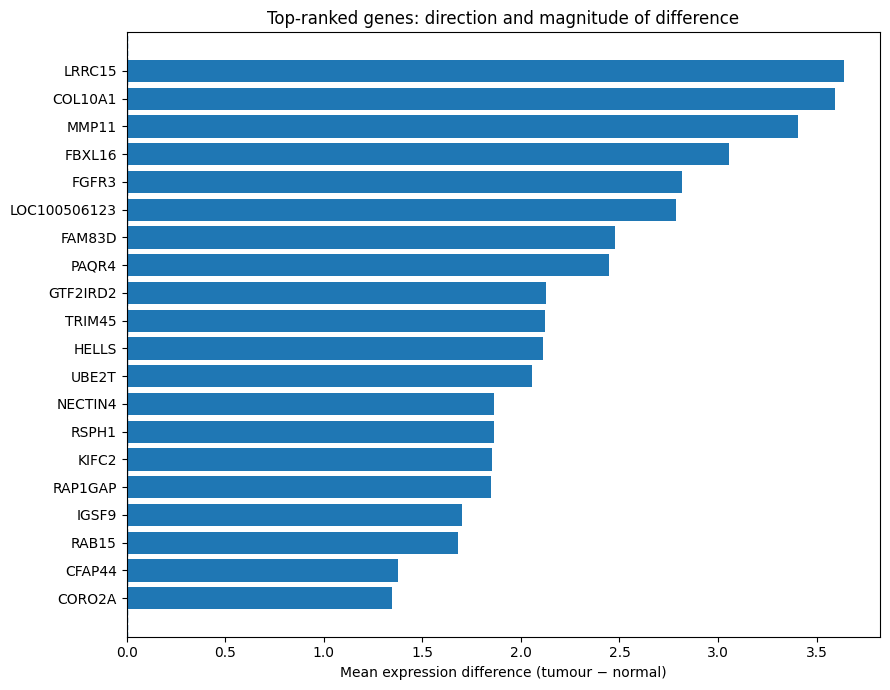

In [9]:
top_n = 20
top_genes = de.head(top_n).copy()
display(top_genes[[
    "gene_symbol", "mean_normal", "mean_tumour",
    "mean_difference_tumour_minus_normal", "p_value", "FDR_q_value", "direction"
]])

plot_genes = top_genes["gene_symbol"].tolist()
plot_df = de.set_index("gene_symbol").loc[plot_genes].sort_values("mean_difference_tumour_minus_normal")

plt.figure(figsize=(9, 7))
plt.barh(plot_df.index, plot_df["mean_difference_tumour_minus_normal"])
plt.axvline(0, linestyle="--", linewidth=1)
plt.xlabel("Mean expression difference (tumour − normal)")
plt.title("Top-ranked genes: direction and magnitude of difference")
plt.tight_layout()
plt.savefig(OUTDIR / "top_gene_differences.png", dpi=180)
plt.show()

## 9. A closer look at a few genes

This cell plots the distribution for the first five genes in the ranked results. The selection is based on the analysis, not on choosing genes after seeing which ones support a preferred story. For a final report, research the biological roles of any genes you discuss using reliable sources such as GeneCards, NCBI Gene, UniProt, or peer-reviewed papers.

/tmp/ipykernel_1473/1939598380.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([vals_normal, vals_tumour], labels=["Normal", "Tumour"], showfliers=False)
/tmp/ipykernel_1473/1939598380.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([vals_normal, vals_tumour], labels=["Normal", "Tumour"], showfliers=False)
/tmp/ipykernel_1473/1939598380.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot([vals_normal, vals_tumour], labels=["Normal", "Tumour"], showfliers=False)
/tmp/ipykernel_1473/1939598380.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been rename

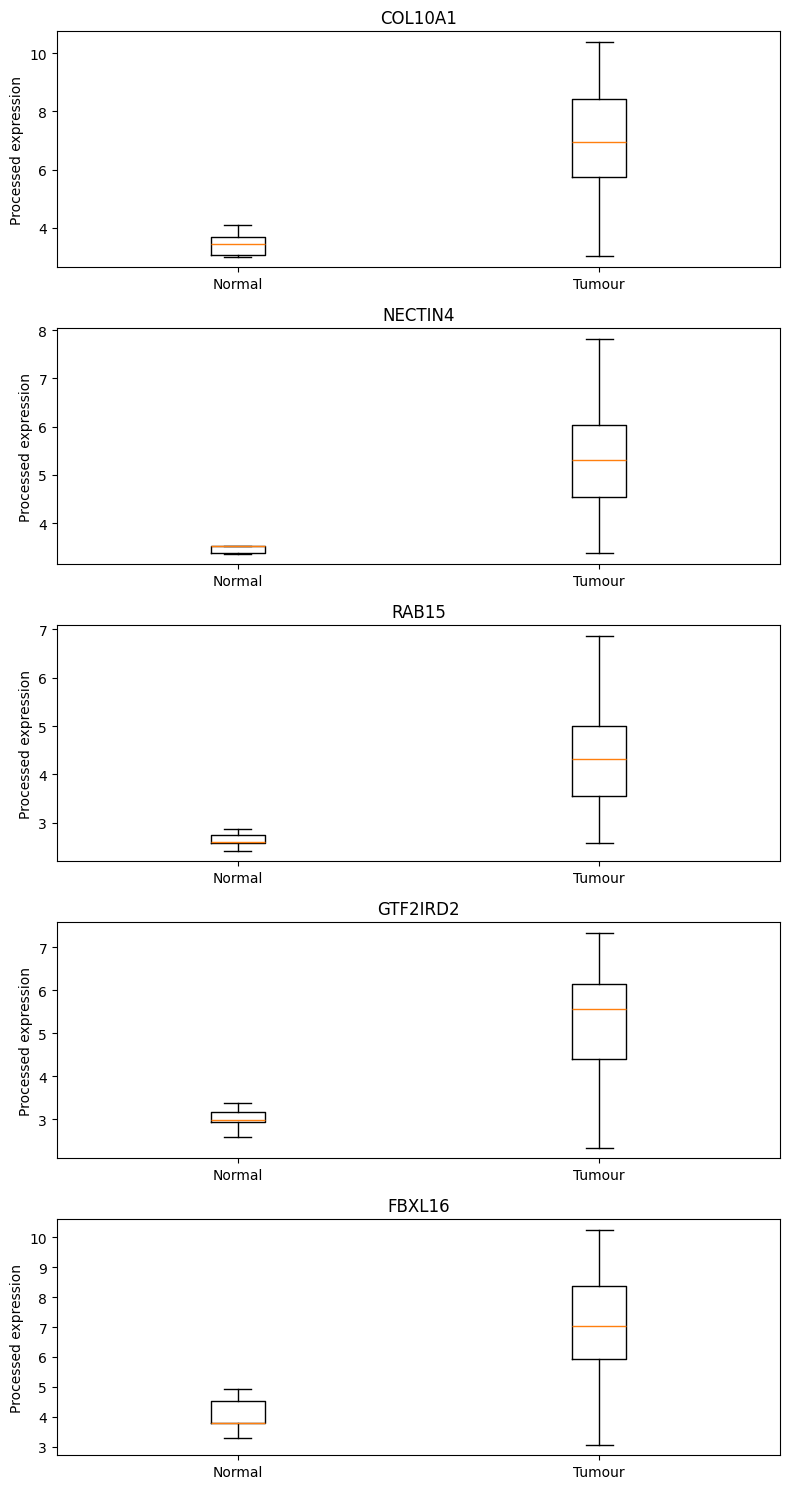

In [10]:
genes_to_plot = de.head(5)["gene_symbol"].tolist()
fig, axes = plt.subplots(len(genes_to_plot), 1, figsize=(8, 3 * len(genes_to_plot)))
if len(genes_to_plot) == 1:
    axes = [axes]

for ax, gene in zip(axes, genes_to_plot):
    vals_normal = gene_expr.loc[gene, normal_cols].astype(float).values
    vals_tumour = gene_expr.loc[gene, tumour_cols].astype(float).values
    ax.boxplot([vals_normal, vals_tumour], labels=["Normal", "Tumour"], showfliers=False)
    ax.set_title(gene)
    ax.set_ylabel("Processed expression")
plt.tight_layout()
plt.savefig(OUTDIR / "top_gene_boxplots.png", dpi=180)
plt.show()

In [11]:
de.to_csv(OUTDIR / "differential_expression_results.csv", index=False)
sample_meta.to_csv(OUTDIR / "sample_metadata_and_labels.csv", index=False)
gene_expr.to_csv(OUTDIR / "gene_level_expression_matrix.csv")
top_genes.to_csv(OUTDIR / "top_20_genes.csv", index=False)

print("Exported files:")
for p in sorted(OUTDIR.iterdir()):
    print(f" - {p.name}: {p.stat().st_size:,} bytes")

Exported files:
 - differential_expression_results.csv: 3,462,715 bytes
 - gene_level_expression_matrix.csv: 31,514,869 bytes
 - sample_median_expression.png: 59,396 bytes
 - sample_metadata_and_labels.csv: 5,764 bytes
 - top_20_genes.csv: 3,343 bytes
 - top_gene_boxplots.png: 112,333 bytes
 - top_gene_differences.png: 79,136 bytes
 - volcano_plot.png: 197,394 bytes
